<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Removing Duplicates and Preparing Survey Data for Analysis**
IBM Skills Network | Data Wrangling Lab | Personalized Portfolio Documentation


### Project overview
Survey datasets may contain repeated records and unanswered questions. If we analyze them without checking data quality, counts, percentages, and summaries can be misleading. In this guided lab, I use Python and Pandas to identify exact duplicate records, remove them, investigate missing values, and prepare selected fields for analysis.

**Business question:** How can we make developer survey responses more consistent and trustworthy before reporting on respondents, education, compensation, and remote-work patterns?

**What this notebook demonstrates:** duplicate detection, record-level cleaning, missing-value assessment, simple imputation, summary statistics, and a categorical chart. The focus is preparing data, not claiming that cleaning alone produces definitive workforce insights.

Estimated time needed: **30** minutes


### Workflow at a glance
1. Load and inspect the survey dataset.
2. Find exact duplicate rows and remove them.
3. Examine missing information and fill missing education values with the most common response.
4. Inspect annual compensation and fill missing values with the median as a lab exercise.
5. Review summary statistics and visualize reported remote-work arrangements.<br>

**Attribution:** This is an IBM Skills Network guided lab. I retained its original tasks and code, adding reader-focused context, interpretation, and critical limitations.

### Objectives


In this lab you will perform the following:


1. Identify duplicate rows  in the dataset.
2. Use suitable techniques to remove duplicate rows and verify the removal.
3. Summarize how to handle missing values appropriately.
4. Use ConvertedCompYearly to normalize compensation data.
   


### Install the Required Libraries


In [16]:
!pip install pandas

#### Step 1: Import Required Libraries


In [17]:
import pandas as pd

**Why we load and preview the data**<br>
The CSV is a table of developer survey responses. Each row represents a response and each column records an attribute or answer. Displaying the first few rows helps confirm the file loaded and shows how values are represented before any changes are made.

#### Step 2: Load the Dataset into a DataFrame



load the dataset using pd.read_csv()


In [18]:
# Define the URL of the dataset
file_path ="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv"

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Display the first few rows to ensure it loaded correctly
print(df.head())


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

**Note: If you are working on a local Jupyter environment, you can use the URL directly in the <code>pandas.read_csv()</code>  function as shown below:**



In [ ]:
#df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv")

**Why duplicate records matter**<br>

If the same survey record appears twice, it can inflate response counts and skew statistics. df.duplicated() flags rows that repeat an earlier row across all columns; it does not flag two different respondents simply because they share an age or work arrangement.

#### Step 3: Identifying Duplicate Rows


**Task 1: Identify Duplicate Rows**
  1. Count the number of duplicate rows in the dataset.
  2. Display the first few duplicate rows to understand their structure.


In [5]:
## Write your code here
no_of_duplicate = df.duplicated().sum()
print("Number of duplicate rows:", no_of_duplicate)

print(df[df.duplicated()].head())

Number of duplicate rows: 10
       ResponseId                      MainBranch                 Age  \
65437           1  I am a developer by profession  Under 18 years old   
65438           2  I am a developer by profession     35-44 years old   
65439           3  I am a developer by profession     45-54 years old   
65440           4           I am learning to code     18-24 years old   
65441           5  I am a developer by profession     18-24 years old   

                Employment RemoteWork   Check  \
65437  Employed, full-time     Remote  Apples   
65438  Employed, full-time     Remote  Apples   
65439  Employed, full-time     Remote  Apples   
65440   Student, full-time        NaN  Apples   
65441   Student, full-time        NaN  Apples   

                                        CodingActivities  \
65437                                              Hobby   
65438  Hobby;Contribute to open-source projects;Other...   
65439  Hobby;Contribute to open-source projects;Other... 

**What the duplicate check found**<br>

The notebook's saved run identified 10 exact duplicate rows. Removing them leaves 65,437 rows and 114 columns, with zero remaining exact duplicates. This verifies the specific duplicate rule used here; it does not establish that every response is genuine or unique in a broader sense.

#### Step 4: Removing Duplicate Rows


**Task 2: Remove Duplicates**
   1. Remove duplicate rows from the dataset using the drop_duplicates() function.
2. Verify the removal by counting the number of duplicate rows after removal .


In [19]:
## Write your code here
df = df.drop_duplicates()

remaining_duplicates = df.duplicated().sum()
print("Number of duplicates after removal:", remaining_duplicates)
print("New dataset structure:", df.shape)

Number of duplicates after removal: 0
New dataset structure: (65437, 114)

**Understanding missing survey answers**<br>

Missing values may mean a question was skipped, not applicable, or unavailable. Here we first count missing entries by column. For EdLevel (education level), the exercise replaces blanks with the mode, or most common observed category. This keeps the field usable for simple summaries, but it can overstate the prevalence of the most common education level.

#### Step 5: Handling Missing Values


**Task 3: Identify and Handle Missing Values**
   1. Identify missing values for all columns in the dataset.
   2. Choose a column with significant missing values (e.g., EdLevel) and impute with the most frequent value.


In [20]:
## Write your code here
missing_value = df.isnull().sum()
print("Missing columns:", missing_value)

df["EdLevel"] = df["EdLevel"].fillna(df["EdLevel"].mode()[0])
print("Remaining missing values:", df["EdLevel"].isnull().sum())

Missing columns: ResponseId                 0
MainBranch                 0
Age                        0
Employment                 0
RemoteWork             10631
                       ...  
JobSatPoints_11        35992
SurveyLength            9255
SurveyEase              9199
ConvertedCompYearly    42002
JobSat                 36311
Length: 114, dtype: int64
Remaining missing values: 0

**Interpreting the compensation step carefully**<br>

ConvertedCompYearly is an annualized compensation field already supplied by the dataset. The code does not perform currency conversion or normalization; it fills missing entries with the observed median. In the saved output, 42,002 of 65,437 records lack this value before filling (about 64.2%). Because so much compensation data is missing, median imputation is useful for practicing Pandas but should not be treated as a reliable salary-distribution estimate. A real compensation study should investigate why values are missing and report observed-data results separately.

#### Step 6: Normalizing Compensation Data


**Task 4: Normalize Compensation Data Using ConvertedCompYearly**
   1. Use the ConvertedCompYearly column for compensation analysis as the normalized annual compensation is already provided.
   2. Check for missing values in ConvertedCompYearly and handle them if necessary.


In [21]:
## Write your code here
missing_compensation = df["ConvertedCompYearly"].isnull().sum()
print("Missing values in Compensation data before removing:", missing_compensation)

median_value = df["ConvertedCompYearly"].median()
df["ConvertedCompYearly"] = df["ConvertedCompYearly"].fillna(median_value)

print("Missing values in compensation data after normalizing:", df["ConvertedCompYearly"].isnull().sum())

Missing values in Compensation data before removing: 42002
Missing values in compensation data after normalizing: 0

**From cleaned data to an initial overview**<br>

The final cell produces numerical summaries and a bar chart of RemoteWork responses. The chart compares the number of respondents in each reported work arrangement. It describes this survey sample, not the prevalence of remote work across all developers. Unanswered RemoteWork entries are excluded from value_counts() by default.

#### Step 7: Summary and Next Steps


**In this lab, you focused on identifying and removing duplicate rows.**

- You handled missing values by imputing the most frequent value in a chosen column.
- You used ConvertedCompYearly for compensation normalization and handled missing values.
- For further analysis, consider exploring other columns or visualizing the cleaned dataset.


Dataset summary:          ResponseId      CompTotal       WorkExp  JobSatPoints_1  \
count  65437.000000   3.374000e+04  29658.000000    29324.000000   
mean   32719.000000  2.963841e+145     11.466957       18.581094   
std    18890.179119  5.444117e+147      9.168709       25.966221   
min        1.000000   0.000000e+00      0.000000        0.000000   
25%    16360.000000   6.000000e+04      4.000000        0.000000   
50%    32719.000000   1.100000e+05      9.000000       10.000000   
75%    49078.000000   2.500000e+05     16.000000       22.000000   
max    65437.000000  1.000000e+150     50.000000      100.000000   

       JobSatPoints_4  JobSatPoints_5  JobSatPoints_6  JobSatPoints_7  \
count    29393.000000    29411.000000    29450.000000     29448.00000   
mean         7.522140       10.060857       24.343232        22.96522   
std         18.422661       21.833836       27.089360        27.01774   
min          0.000000        0.000000        0.000000         0.00000   
25%  

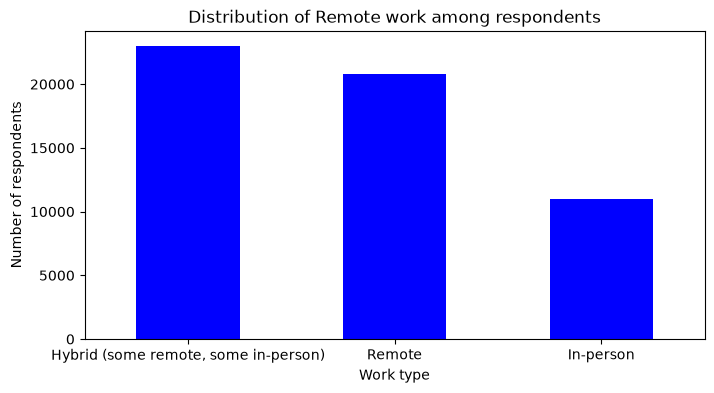

In [26]:
## Write your code here
import matplotlib.pyplot as plt

print("Dataset summary:", df.describe())

remote_distribution = df["RemoteWork"].value_counts()
remote_distribution.plot(kind="bar", color="blue", figsize=(8, 4))
plt.title("Distribution of Remote work among respondents")
plt.ylabel("Number of respondents")
plt.xlabel("Work type")
plt.xticks(rotation=0)
plt.show()

##### Key takeaways
- 10 exact duplicate records were identified and removed, leaving 65,437 rows × 114 columns in the saved run.
- The EdLevel field was filled using its most frequent observed category, illustrating one simple approach to missing categorical data.
- The compensation field had 42,002 missing values before median filling. This is a substantial limitation, not merely a technical inconvenience.
- The remote-work chart provides an accessible first look at the survey responses, but does not establish causation or population-wide trends.

##### Limitations and next steps
The notebook is a guided cleaning exercise. Exact-row checks may miss near-duplicates. Mode and median filling alter the original data distribution, and compensation nonresponse may not be random. The CompTotal summary also contains an extreme value in the saved output, so raw compensation statistics deserve separate validation before interpretation.

For a more rigorous follow-up, I would preserve original columns or missing-value flags, check uniqueness of ResponseId, compare summaries before and after cleaning, examine outliers, and report compensation using only observed values alongside missingness rates.

**Skills demonstrated**<br>
Python · Pandas · Data cleaning · Duplicate detection · Missing-value analysis · Mode/median imputation · Descriptive statistics · Matplotlib · Data quality communication

**Source and attribution:** IBM Skills Network learning material. The original lab content, Skills Network branding, and IBM copyright notice are retained.

<!--
## Change Log

|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11-05|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|

--!>


Copyright © IBM Corporation. All rights reserved.
